# Risk inference and crowding


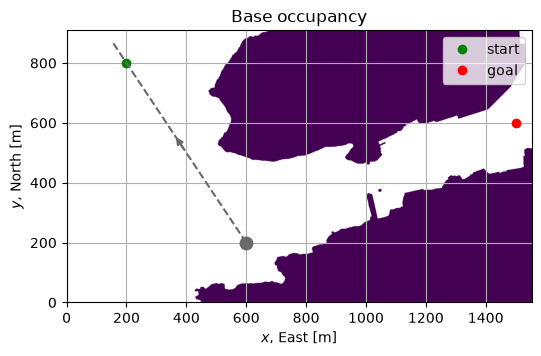

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from cartoblobpy.graph import Graph

from risk_informed_planner.obstacles import *
from risk_informed_planner.visualization import *

g = Graph()
g.load_from_yaml("../maps/kristiansund_bridge/map.yaml")
g.start = (200.0, 800.0)
g.goal = (1500, 600.0)
obstacles = [
    LinearDynamicObstacle.create(
        start_pose=(600.0, 200.0), end_pose=(200.0, 800.0), velocity=2.0
    ),
]

fig, ax = plt.subplots(figsize=(6, 6))


g.plot(ax=ax)
plot_obstacles(obstacles, ax=ax, max_time=400.0)
plt.grid(True)

## Notation

Symbols match the paper's `Real-time requirements` subsection.

| code | paper | meaning |
|---|---|---|
| `MAX_NODES` | $N_{\max}$ | node budget |
| `len(nodes)` | $\lvert V \rvert$ | current tree size |
| `nbrad_m` | $\rho_{\mathrm{nb}}$ | neighbourhood radius |
| `A_m2` | $A$ | free area |
| `kappa` | $\kappa$ | fraction of candidate edges reaching the cost computation |
| `nbar` | $\bar{n}$ | risk samples per evaluated edge |
| `ncalls_tot` | $C_{\mathrm{tot}}$ | risk evaluations per planning run |
| `t_r` | $t_{r}$ | wall-clock time of one risk evaluation |
| `deadline_s` | $T$ | replanning deadline |

$t_{r}$ covers evidence construction, BBN inference *and* the severity-to-cost
mapping, so it is labelled "risk evaluation" rather than "BBN call" throughout.


## Create the experiment matrix

In [2]:
import itertools

alpha_values = [0.1]
beta_values = [100.0]
gamma_values = [0.6]
max_nodes = [750, 1000, 1250, 1500, 1750, 2000, 2250, 2500]
number_of_runs_per_configuration = 5

# create a list of all configurations to test
keys = [
    "ALPHA",
    "BETA",
    "GAMMA",
    "MAX_NODES",
    "RUN_ID",
]

experiment_matrix = [
    dict(zip(keys, values))
    for values in itertools.product(
        alpha_values,
        beta_values,
        gamma_values,
        max_nodes,
        range(number_of_runs_per_configuration),
    )
]

len(experiment_matrix), experiment_matrix[:2]

(40,
 [{'ALPHA': 0.1, 'BETA': 100.0, 'GAMMA': 0.6, 'MAX_NODES': 750, 'RUN_ID': 0},
  {'ALPHA': 0.1, 'BETA': 100.0, 'GAMMA': 0.6, 'MAX_NODES': 750, 'RUN_ID': 1}])

In [3]:
# Wall-clock time [s] per risk evaluation, pooled across runs, keyed by MAX_NODES.
risk_compute_times_by_max_nodes = {n: [] for n in max_nodes}

# Number of risk evaluations in a single run, one entry per run,
# keyed by MAX_NODES. This is ncalls_tot for that configuration.
ncalls_by_max_nodes = {n: [] for n in max_nodes}

## Run the experiments and collect results

In [4]:
import time

from risk_informed_planner.config import Config
from risk_informed_planner.risk.cost_model import *
from risk_informed_planner.risk.dynamic_risk import DynamicRisk
from risk_informed_planner.planner import (
    RiskAwareAngleCostRRTStarSearch,
    progress_bar,
)
from risk_informed_planner.utils import Node
from risk_informed_planner.risk import cost_model

for idx, exp in enumerate(experiment_matrix):
    print(f"Running configuration ({idx + 1}/{len(experiment_matrix)}): {exp}")

    start = Node(g.start[0], g.start[1], 0)
    goal = Node(g.goal[0], g.goal[1], -1)

    cfg = Config(
        X_LIMITS=(0, g.width),
        Y_LIMITS=(0, g.height),
        STEP_SIZE=50,
        GOAL_RADIUS=75,
        NEIGHBOR_RADIUS=150,
        MAX_NODES=exp["MAX_NODES"],
        ALPHA=exp["ALPHA"],
        BETA=exp["BETA"],
        GAMMA=exp["GAMMA"],
        RISK_CUTOFF=np.inf,
        MAX_TURN_ANGLE=np.pi / 4,
        RISK_SAMPLE_SPACING=30.0,
        RISK_AGGREGATION="max",
    )

    min_depth = 10.0
    risk_model = DynamicRisk(
        max_distance_from_shore=150.0,
        lookahead_distance=150.0,
        graph=g,
        obstacles=obstacles,
        max_dcpa_for_collision_risk=50.0,
        max_tcpa_for_collision_risk=120.0,
        max_relative_velocity_for_collision_risk=5.0,
        grounding_depth_hard_limit=min_depth,
        desired_speed=3.0,
        cost_model=cost_model.NormalizedExpectedLoss(),
    )

    free_check_method = RiskAwareAngleCostRRTStarSearch.FreeCheckMethod.OCCUPANCY

    path_planner = RiskAwareAngleCostRRTStarSearch(
        start=start,
        goal=goal,
        graph=g,
        cfg=cfg,
        risk_model=risk_model,
        record_bbn_snapshots=False,
        min_depth=min_depth,
        free_check_method=free_check_method,
        callback_functions=[progress_bar],
    )

    start_time = time.perf_counter()
    nodes, path = path_planner()
    total_computation_time = time.perf_counter() - start_time
    print(
        f"Planning completed in {total_computation_time:.2f} seconds "
        f"({path_planner.risk_evaluations} risk evaluations)."
    )
    print("\n")

    risk_compute_times_by_max_nodes[exp["MAX_NODES"]].extend(path_planner.risk_compute_times)
    ncalls_by_max_nodes[exp["MAX_NODES"]].append(path_planner.risk_evaluations)


# save stats to a file with numpy utilities. Dicts round-trip fine through
# np.savez as pickled 0-d object arrays; load back with allow_pickle=True and
# `.item()`.

np.savez(
    "experiment_compute_average_risk_compute_time_stats.npz",
    alpha_values=alpha_values,
    beta_values=beta_values,
    gamma_values=gamma_values,
    max_nodes=max_nodes,
    number_of_runs_per_configuration=number_of_runs_per_configuration,
    risk_compute_times_by_max_nodes=risk_compute_times_by_max_nodes,
    ncalls_by_max_nodes=ncalls_by_max_nodes,
)


Running configuration (1/40): {'ALPHA': 0.1, 'BETA': 100.0, 'GAMMA': 0.6, 'MAX_NODES': 750, 'RUN_ID': 0}


Progress:   0%|          | 0/750 [00:00<?, ?node/s]

Planning completed in 6.31 seconds (33369 risk evaluations).


Running configuration (2/40): {'ALPHA': 0.1, 'BETA': 100.0, 'GAMMA': 0.6, 'MAX_NODES': 750, 'RUN_ID': 1}


Progress:   0%|          | 0/750 [00:00<?, ?node/s]

Planning completed in 6.60 seconds (31737 risk evaluations).


Running configuration (3/40): {'ALPHA': 0.1, 'BETA': 100.0, 'GAMMA': 0.6, 'MAX_NODES': 750, 'RUN_ID': 2}


Progress:   0%|          | 0/750 [00:00<?, ?node/s]

... (71 outputs left out)

Progress:   0%|          | 0/2500 [00:00<?, ?node/s]

Planning completed in 57.92 seconds (350907 risk evaluations).


Running configuration (40/40): {'ALPHA': 0.1, 'BETA': 100.0, 'GAMMA': 0.6, 'MAX_NODES': 2500, 'RUN_ID': 4}


Progress:   0%|          | 0/2500 [00:00<?, ?node/s]

Planning completed in 57.83 seconds (357115 risk evaluations).




## Per-evaluation cost

risk evaluations pooled : 6,804,607
mean t_r                : 0.1061 ms
median t_r              : 0.0911 ms
std. deviation          : 0.2528 ms
min / max               : 0.0713 / 227.4510 ms

  N_max | mean t_r [ms]
-------------------------
    750 |        0.1161
   1000 |        0.1169
   1250 |        0.1053
   1500 |        0.1069
   1750 |        0.1099
   2000 |        0.1097
   2250 |        0.1019
   2500 |        0.1026


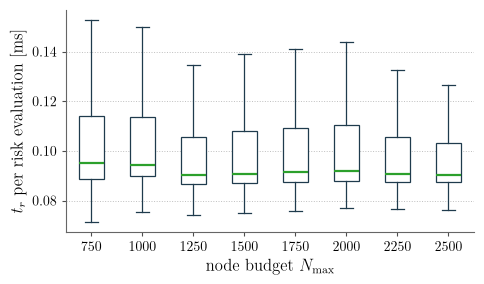

In [5]:
"""Figure: distribution of t_r against the node budget.

Sanity check -- one risk evaluation should not get more expensive because the
tree has more nodes in it, so this should be flat.
"""

import matplotlib.pyplot as plt
import numpy as np

# Discard the first WARMUP calls of each configuration: caches, allocation and
# any lazy network compilation land there and inflate the small-budget means.
WARMUP = 200

data = np.load("experiment_compute_average_risk_compute_time_stats.npz", allow_pickle=True)
risk_compute_times_by_max_nodes = data["risk_compute_times_by_max_nodes"].item()
nodes_sorted = sorted(risk_compute_times_by_max_nodes)

t_r_ms = {
    n: np.asarray(risk_compute_times_by_max_nodes[n])[WARMUP:] * 1e3
    for n in nodes_sorted
}

pooled = np.concatenate([t_r_ms[n] for n in nodes_sorted])
print(f"risk evaluations pooled : {pooled.size:,}")
print(f"mean t_r                : {pooled.mean():.4f} ms")
print(f"median t_r              : {np.median(pooled):.4f} ms")
print(f"std. deviation          : {pooled.std():.4f} ms")
print(f"min / max               : {pooled.min():.4f} / {pooled.max():.4f} ms")
print()
print(f"{'N_max':>7} | {'mean t_r [ms]':>13}")
print("-" * 25)
for n in nodes_sorted:
    print(f"{n:>7} | {t_r_ms[n].mean():>13.4f}")

INK = "#1f3b4d"
MEDIAN = "#2ca02c"

enable_latex(True)

fig, ax = plt.subplots(figsize=(5.0, 3.0))

ax.boxplot(
    [t_r_ms[n] for n in nodes_sorted],
    positions=np.arange(len(nodes_sorted)),
    widths=0.5,
    patch_artist=True,
    showfliers=False,
    zorder=3,
    boxprops=dict(facecolor="white", edgecolor=INK, linewidth=0.9),
    medianprops=dict(color=MEDIAN, linewidth=1.6),
    whiskerprops=dict(color=INK, linewidth=0.9),
    capprops=dict(color=INK, linewidth=0.9),
)

ax.set_xticks(np.arange(len(nodes_sorted)))
ax.set_xticklabels(nodes_sorted)
ax.set_xlabel(r"node budget $N_{\max}$")
ax.set_ylabel(r"$t_{r}$ per risk evaluation [ms]")

ax.set_axisbelow(True)
ax.yaxis.grid(True, linestyle=":", linewidth=0.7, color="0.75")
ax.xaxis.grid(False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color("0.4")
ax.tick_params(colors="0.3", length=3)
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_color("black")

fig.tight_layout()
fig.savefig("risk_compute_time_per_call_vs_nodes.png", bbox_inches="tight", dpi=300)
fig.savefig("risk_compute_time_per_call_vs_nodes.pdf", bbox_inches="tight")
plt.show()


## Real-time budget

Evaluates the budget inequality

$$ t_{r} \;\le\; \frac{T \, A}{\kappa \, \bar{n} \, \pi \rho_{\mathrm{nb}}^{2} N_{\max}^{2}}
        \;=\; \frac{T}{C_{\mathrm{tot}}(N_{\max})} , $$

using the *measured* $C_{\mathrm{tot}}$ so that $\kappa$ and $\bar{n}$ need not
be guessed. Since $C_{\mathrm{tot}} \propto N_{\max}^{2}$ while $t_{r}$ is flat,
the ceiling falls quadratically and the two cross at the largest budget that
meets the deadline.

Two candidate deadlines are printed:

* `segment` -- $\eta / v_{\mathrm{d}}$, the time to traverse one planner
  segment, i.e. how long before the vessel commits to the next one;
* `sensing` -- $\min\{t_{\mathrm{CPA}}, d_{\mathrm{look}} / v_{\mathrm{d}}\}$.

`segment` is the tighter and more defensible of the two, since
$d_{\mathrm{look}}$ is a perception horizon rather than a control time
constant. Set `DEADLINE_MODE` to match whichever the paper states.


In [6]:
"""Fit C_tot(N_max), pick the deadline, and locate the crossing."""

import operator

import numpy as np

DEADLINE_MODE = "segment"   # "segment" or "sensing"
WARMUP = 200

data = np.load("experiment_compute_average_risk_compute_time_stats.npz", allow_pickle=True)
risk_compute_times_by_max_nodes = data["risk_compute_times_by_max_nodes"].item()
ncalls_by_max_nodes = data["ncalls_by_max_nodes"].item()
nodes_sorted = sorted(ncalls_by_max_nodes)

# --- geometry, independent of N_max ---
nbrad_m = cfg.NEIGHBOR_RADIUS
free_mask = g.free_space_mask(threshold=0.5, op=operator.le)
A_m2 = free_mask.sum() * (g.resolution**2)

# --- deadline ---
segment_s = cfg.STEP_SIZE / risk_model.desired_speed
sensing_s = min(
    risk_model.max_tcpa_for_collision_risk,
    risk_model.lookahead_distance / risk_model.desired_speed,
)
deadline_s = segment_s if DEADLINE_MODE == "segment" else sensing_s

# --- measured quantities ---
xs = np.asarray(nodes_sorted, float)
ncalls = np.asarray([np.mean(ncalls_by_max_nodes[n]) for n in nodes_sorted], float)
t_r_ms = np.asarray(
    [np.mean(np.asarray(risk_compute_times_by_max_nodes[n])[WARMUP:]) * 1e3
     for n in nodes_sorted], float
)
t_r_bar = float(t_r_ms.mean())

# --- C_tot = c * N_max^2, least squares through the origin ---
c_quad = float(np.sum(ncalls * xs**2) / np.sum(xs**4))
kappa_nbar = c_quad * A_m2 / (np.pi * nbrad_m**2)

# --- crossing: T / (c N^2) = t_r  =>  N = sqrt(T / (c t_r)) ---
n_cross = float(np.sqrt((deadline_s * 1e3) / (c_quad * t_r_bar)))

budget_ms = (deadline_s * 1e3) / ncalls

print(f"deadline mode : {DEADLINE_MODE}")
print(f"  segment  eta/v_d              = {segment_s:.0f} s")
print(f"  sensing  min(tcpa, dlook/v_d) = {sensing_s:.0f} s")
print(f"  -> T = {deadline_s:.0f} s")
print()
print(f"rho_nb = {nbrad_m:.0f} m,  A = {A_m2:,.0f} m^2")
print(f"C_tot(N) ~ {c_quad:.5f} * N^2   =>  kappa*nbar = {kappa_nbar:.3f}")
print(f"mean t_r = {t_r_bar:.4f} ms  (first {WARMUP} calls per config dropped)")
print()
header = f"{'N_max':>7} | {'C_tot':>10} | {'t_r [ms]':>9} | {'budget [ms]':>11} | {'ratio':>6}"
print(header)
print("-" * len(header))
for n, cc, tm, bm in zip(nodes_sorted, ncalls, t_r_ms, budget_ms):
    print(f"{n:>7} | {cc:>10,.0f} | {tm:>9.4f} | {bm:>11.4f} | {tm / bm:>5.2f}x")
print()
print(f"-> budget and measured t_r cross at N_max = {n_cross:.0f}")


deadline mode : segment
  segment  eta/v_d              = 17 s
  sensing  min(tcpa, dlook/v_d) = 50 s
  -> T = 17 s

rho_nb = 150 m,  A = 769,152 m^2
C_tot(N) ~ 0.05706 * N^2   =>  kappa*nbar = 0.621
mean t_r = 0.1087 ms  (first 200 calls per config dropped)

  N_max |      C_tot |  t_r [ms] | budget [ms] |  ratio
-------------------------------------------------------
    750 |     32,417 |    0.1161 |      0.5141 |  0.23x
   1000 |     58,749 |    0.1169 |      0.2837 |  0.41x
   1250 |     91,128 |    0.1053 |      0.1829 |  0.58x
   1500 |    128,319 |    0.1069 |      0.1299 |  0.82x
   1750 |    178,254 |    0.1099 |      0.0935 |  1.18x
   2000 |    232,430 |    0.1097 |      0.0717 |  1.53x
   2250 |    287,280 |    0.1019 |      0.0580 |  1.76x
   2500 |    352,664 |    0.1026 |      0.0473 |  2.17x

-> budget and measured t_r cross at N_max = 1640


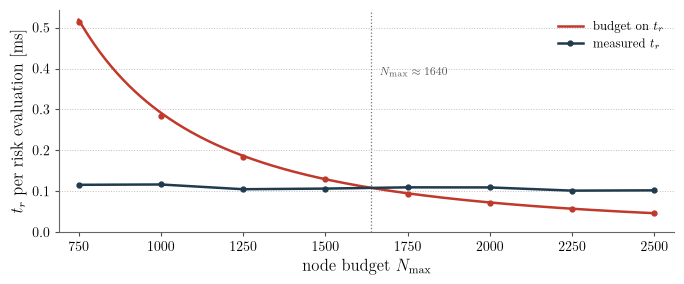

In [7]:
"""Figure: measured t_r against the budget ceiling."""

import matplotlib.pyplot as plt
import numpy as np

MEASURED = "#1f3b4d"
BUDGET = "#c0392b"

enable_latex(True)

fig, ax = plt.subplots(figsize=(7.0, 3.0))

# Smooth ceiling from the fitted C_tot, so the quadratic fall is visible
# rather than implied by eight straight segments.
grid = np.linspace(xs.min(), xs.max(), 300)
ax.plot(grid, (deadline_s * 1e3) / (c_quad * grid**2),
        color=BUDGET, lw=1.8, label=r"budget on $t_{r}$")
ax.plot(xs, budget_ms, ls="none", marker="o", markersize=3.5, color=BUDGET)

ax.plot(xs, t_r_ms, color=MEASURED, lw=1.8, marker="o", markersize=3.5,
        label=r"measured $t_{r}$")

# Mark the crossing explicitly -- the region where the curves separate is too
# thin to read as a shaded band.
if xs.min() <= n_cross <= xs.max():
    ax.axvline(n_cross, color="0.45", lw=0.9, ls=":", zorder=1)
    ax.annotate(
        rf"$N_{{\max}} \approx {n_cross:.0f}$",
        xy=(n_cross, ax.get_ylim()[1] * 0.72),
        xytext=(6, 0), textcoords="offset points",
        fontsize=8, color="0.35", ha="left", va="center",
    )

ax.set_xlabel(r"node budget $N_{\max}$")
ax.set_ylabel(r"$t_{r}$ per risk evaluation [ms]")
ax.set_ylim(bottom=0)
ax.set_xlim(xs.min() - 60, xs.max() + 60)

ax.set_axisbelow(True)
ax.yaxis.grid(True, linestyle=":", linewidth=0.7, color="0.75")
ax.xaxis.grid(False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color("0.4")
ax.tick_params(colors="0.3", length=3)
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_color("black")

ax.legend(frameon=False, loc="upper right", fontsize=9)

fig.tight_layout()
fig.savefig("risk_compute_time_budget_vs_measured.png", bbox_inches="tight", dpi=300)
fig.savefig("risk_compute_time_budget_vs_measured.pdf", bbox_inches="tight")
plt.show()


## Crowding: neighbourhood size and cost per node

Validates Eq.~(nbrs) and Eq.~(total) against a single run, and measures the two
constants the paper needs.

The expected neighbourhood size under uniform sampling is

$$\mathbb{E}[|\mathcal{N}|] = \frac{\pi \rho_{\mathrm{nb}}^2}{A} \, |V| ,$$

so the number of risk evaluations spent per node added should grow *linearly*
in the tree size $|V|$, and the cumulative count quadratically.

A single run to the largest budget traces the whole $|V|$ range, so this does
not need the sweep. Three instrumented quantities:

* `k_count`  -- size of each radius query, i.e. measured $|\mathcal{N}|$;
* `s_samples` -- risk samples per edge, i.e. measured $\bar{n}$;
* `c_calls`  -- cumulative `risk_evaluations`, sampled once per iteration.

From these, $\kappa$ falls out as the ratio between the observed cost per node
and $2\,\bar{n}\,\mathbb{E}[|\mathcal{N}|]$.

> **Note.** This notebook runs with `RISK_CUTOFF = np.inf`, so the cutoff gate
> never rejects an edge. The $\kappa$ measured here reflects the collision
> check, the turn limit and the parentless-neighbour skip only. Re-run with the
> finite cutoff used in the results if the paper quotes both.


In [8]:
"""Instrumentation: wrap the planner's neighbour query and sample count.

Monkey-patching keeps this notebook self-contained -- no library edits. Both
methods are public, so no name mangling to work around.

`get_closest_neighbors` delegates to `get_neighbors`, so recording inside
`get_neighbors` captures the pure radius query in either case; the
MAX_NEIGHBORS_RISK_RENEWAL truncation happens afterwards and is not counted
here (it folds into kappa instead).
"""

import numpy as np

from risk_informed_planner.planner import (
    RiskAwareAngleCostRRTStarSearch as _Planner,
)


class CrowdingRecorder:
    """Collects the three traces needed for the crowding figure."""

    def __init__(self):
        self.reset()

    def reset(self):
        self.k_tree = []     # |V| at the time of each radius query
        self.k_count = []    # size of that radius query
        self.s_samples = []  # risk samples on each evaluated edge
        self.c_tree = []     # |V| at each iteration
        self.c_calls = []    # cumulative risk_evaluations at each iteration

    def callback(self, nodes, path, obj):
        self.c_tree.append(len(nodes))
        self.c_calls.append(obj.risk_evaluations)


REC = CrowdingRecorder()

if not getattr(_Planner, "_crowding_patched", False):
    _orig_get_neighbors = _Planner.get_neighbors
    _orig_num_risk_samples = _Planner.num_risk_samples

    def _get_neighbors(self, new_node):
        out = _orig_get_neighbors(self, new_node)
        REC.k_tree.append(len(self.nodes))
        REC.k_count.append(len(out))
        return out

    def _num_risk_samples(self, edge_len):
        n = _orig_num_risk_samples(self, edge_len)
        REC.s_samples.append(n)
        return n

    _Planner.get_neighbors = _get_neighbors
    _Planner.num_risk_samples = _num_risk_samples
    _Planner._crowding_patched = True

print("instrumentation active")


instrumentation active


In [9]:
"""One instrumented run at the largest budget, repeated a few times.

A single run traces |V| from 1 to MAX_NODES, so the whole x-range of the
figure comes from one run. Repeats only smooth the curve.
"""

import operator
import time

from risk_informed_planner.config import Config
from risk_informed_planner.risk import cost_model
from risk_informed_planner.risk.dynamic_risk import DynamicRisk
from risk_informed_planner.planner import (
    RiskAwareAngleCostRRTStarSearch,
    progress_bar,
)
from risk_informed_planner.utils import Node

CROWDING_MAX_NODES = max(max_nodes)
CROWDING_RUNS = 3

REC.reset()

for run_id in range(CROWDING_RUNS):
    print(f"Crowding run {run_id + 1}/{CROWDING_RUNS} (MAX_NODES={CROWDING_MAX_NODES})")

    start = Node(g.start[0], g.start[1], 0)
    goal = Node(g.goal[0], g.goal[1], -1)

    cfg = Config(
        X_LIMITS=(0, g.width),
        Y_LIMITS=(0, g.height),
        STEP_SIZE=50,
        GOAL_RADIUS=75,
        NEIGHBOR_RADIUS=150,
        MAX_NODES=CROWDING_MAX_NODES,
        ALPHA=alpha_values[0],
        BETA=beta_values[0],
        GAMMA=gamma_values[0],
        RISK_CUTOFF=np.inf,
        MAX_TURN_ANGLE=np.pi / 4,
        RISK_SAMPLE_SPACING=30.0,
        RISK_AGGREGATION="max",
    )

    min_depth = 10.0
    risk_model = DynamicRisk(
        max_distance_from_shore=150.0,
        lookahead_distance=150.0,
        graph=g,
        obstacles=obstacles,
        max_dcpa_for_collision_risk=50.0,
        max_tcpa_for_collision_risk=120.0,
        max_relative_velocity_for_collision_risk=5.0,
        grounding_depth_hard_limit=min_depth,
        desired_speed=3.0,
        cost_model=cost_model.NormalizedExpectedLoss(),
    )

    path_planner = RiskAwareAngleCostRRTStarSearch(
        start=start,
        goal=goal,
        graph=g,
        cfg=cfg,
        risk_model=risk_model,
        record_bbn_snapshots=False,
        min_depth=min_depth,
        free_check_method=RiskAwareAngleCostRRTStarSearch.FreeCheckMethod.OCCUPANCY,
        callback_functions=[progress_bar, REC.callback],
    )

    t0 = time.perf_counter()
    nodes, path = path_planner()
    print(
        f"  done in {time.perf_counter() - t0:.1f} s, "
        f"{path_planner.risk_evaluations:,} risk evaluations\n"
    )

# --- geometry (independent of the run) ---
nbrad_m = cfg.NEIGHBOR_RADIUS
free_mask = g.free_space_mask(threshold=0.5, op=operator.le)
A_m2 = free_mask.sum() * (g.resolution**2)

np.savez(
    "experiment_crowding_stats.npz",
    k_tree=np.array(REC.k_tree),
    k_count=np.array(REC.k_count),
    s_samples=np.array(REC.s_samples),
    c_tree=np.array(REC.c_tree),
    c_calls=np.array(REC.c_calls),
    nbrad_m=nbrad_m,
    A_m2=A_m2,
    crowding_max_nodes=CROWDING_MAX_NODES,
    crowding_runs=CROWDING_RUNS,
)

print(f"nbrad = {nbrad_m:.0f} m,  A = {A_m2:,.0f} m^2")


Crowding run 1/3 (MAX_NODES=2500)


Progress:   0%|          | 0/2500 [00:00<?, ?node/s]

  done in 61.0 s, 359,821 risk evaluations

Crowding run 2/3 (MAX_NODES=2500)


Progress:   0%|          | 0/2500 [00:00<?, ?node/s]

  done in 58.3 s, 349,580 risk evaluations

Crowding run 3/3 (MAX_NODES=2500)


Progress:   0%|          | 0/2500 [00:00<?, ?node/s]

  done in 60.1 s, 352,299 risk evaluations

nbrad = 150 m,  A = 769,152 m^2


In [10]:
"""Reduce the traces to kappa, nbar, and the two curves for the figure."""

import numpy as np

d = np.load("experiment_crowding_stats.npz")
k_tree, k_count = d["k_tree"], d["k_count"]
s_samples = d["s_samples"]
c_tree, c_calls = d["c_tree"], d["c_calls"]
nbrad_m, A_m2 = float(d["nbrad_m"]), float(d["A_m2"])


def binned_mean(x, y, n_bins=24, min_count=5):
    """Mean of y over equal-width bins in x. Drops sparse bins."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    edges = np.linspace(x.min(), x.max(), n_bins + 1)
    idx = np.clip(np.digitize(x, edges) - 1, 0, n_bins - 1)
    xs, ys = [], []
    for b in range(n_bins):
        m = idx == b
        if m.sum() >= min_count:
            xs.append(x[m].mean())
            ys.append(y[m].mean())
    return np.asarray(xs), np.asarray(ys)


# --- panel A: measured vs predicted neighbourhood size ---
kx, ky = binned_mean(k_tree, k_count)
pred_k = lambda v: np.pi * nbrad_m**2 * np.asarray(v, float) / A_m2

# --- panel B: risk evaluations spent per node added ---
# Runs are concatenated in c_tree, so split where |V| resets.
splits = np.flatnonzero(np.diff(c_tree) < 0) + 1
rate_x, rate_y = [], []
for seg_t, seg_c in zip(np.split(c_tree, splits), np.split(c_calls, splits)):
    dv, dc = np.diff(seg_t), np.diff(seg_c)
    ok = dv > 0
    rate_x.append(seg_t[1:][ok])
    rate_y.append(dc[ok] / dv[ok])
rate_x, rate_y = np.concatenate(rate_x), np.concatenate(rate_y)
rx, ry = binned_mean(rate_x, rate_y)

# --- the two constants ---
nbar = float(s_samples.mean())

# Least-squares slope through the origin of (cost per node) vs |V|.
slope = float(np.sum(rate_x * rate_y) / np.sum(rate_x**2))
kappa = slope * A_m2 / (2.0 * nbar * np.pi * nbrad_m**2)

# Boundary deficit: how far the measured neighbourhood falls below the
# interior-point prediction, which is an upper bound.
deficit = float(np.mean(ky / pred_k(kx)))

print(f"nbar   (risk samples per edge)     = {nbar:.2f}")
print(f"kappa  (fraction reaching cost)    = {kappa:.3f}")
print(f"        of which boundary clipping = {deficit:.3f} of the predicted |N|")
print(f"        so kappa net of geometry   = {kappa / deficit:.3f}")
print()
print(f"cost per node = {slope:.4f} * |V|   [risk evaluations]")
print(f"=> ncalls_tot(N) ~ {slope / 2:.4f} * N^2")
for n in (1000, 2500, 5000):
    print(f"     N = {n:>5}:  {slope / 2 * n**2:>12,.0f} evaluations")


nbar   (risk samples per edge)     = 3.63
kappa  (fraction reaching cost)    = 0.169
        of which boundary clipping = 0.837 of the predicted |N|
        so kappa net of geometry   = 0.202

cost per node = 0.1127 * |V|   [risk evaluations]
=> ncalls_tot(N) ~ 0.0563 * N^2
     N =  1000:        56,348 evaluations
     N =  2500:       352,173 evaluations
     N =  5000:     1,408,691 evaluations


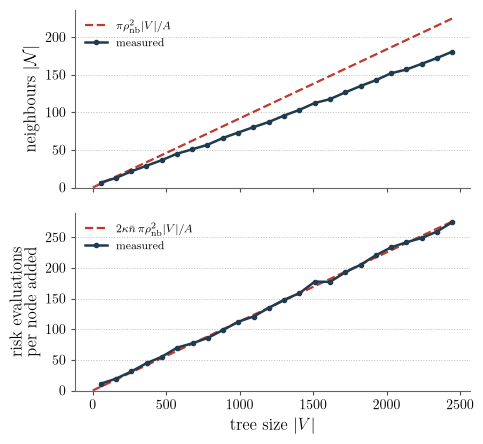

In [11]:
"""Figure: crowding -- neighbourhood size and cost per node."""

import matplotlib.pyplot as plt
import numpy as np

INK = "#1f3b4d"
PRED = "#c0392b"

enable_latex(True)

fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(5.0, 4.6), sharex=True)

vs = np.linspace(1, max(kx.max(), rx.max()), 200)

# --- top: neighbourhood size ---
ax_top.plot(vs, pred_k(vs), color=PRED, lw=1.6, ls="--",
            label=r"$\pi \rho_{\mathrm{nb}}^{2} |V| / A$")
ax_top.plot(kx, ky, color=INK, lw=1.8, marker="o", markersize=3.0,
            label="measured")
ax_top.set_ylabel(r"neighbours $|\mathcal{N}|$")
ax_top.legend(frameon=False, loc="upper left", fontsize=8)

# --- bottom: risk evaluations per node added ---
ax_bot.plot(vs, slope * vs, color=PRED, lw=1.6, ls="--",
            label=r"$2 \kappa \bar{n} \, \pi \rho_{\mathrm{nb}}^{2} |V| / A$")
ax_bot.plot(rx, ry, color=INK, lw=1.8, marker="o", markersize=3.0,
            label="measured")
ax_bot.set_xlabel(r"tree size $|V|$")
ax_bot.set_ylabel("risk evaluations\nper node added")
ax_bot.legend(frameon=False, loc="upper left", fontsize=8)

for ax in (ax_top, ax_bot):
    ax.set_ylim(bottom=0)
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, linestyle=":", linewidth=0.7, color="0.75")
    ax.xaxis.grid(False)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("0.4")
    ax.tick_params(colors="0.3", length=3)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_color("black")

fig.tight_layout()
fig.savefig("crowding_neighbours_and_calls.png", bbox_inches="tight", dpi=300)
fig.savefig("crowding_neighbours_and_calls.pdf", bbox_inches="tight")
plt.show()
